# 02 — Avaliação do modelo de risco de atraso

Lê os arquivos gerados por `python -m scripts.train_model` (em `backend/models/`) e produz
as análises do **RNF03**: métricas, curvas ROC e Precision-Recall, matriz de confusão,
importância das features e validação das faixas de risco.

> Todas as métricas são do **período de teste (abr a ago/2018)**, que o modelo não viu no treino.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve, roc_curve

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "backend").is_dir())
MODELS = ROOT / "backend" / "models"

report = json.loads((MODELS / "metrics.json").read_text(encoding="utf-8"))
preds = pd.read_parquet(MODELS / "test_predictions.parquet")
metrics = report["metrics_test"]

COLOR, GRAY = "#2a78d6", "#8a8984"
pd.set_option("display.float_format", "{:,.3f}".format)


def style(ax, title):
    ax.set_title(title, loc="left", fontsize=12)
    ax.grid(alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)


print(f"Modelo treinado em: {report['trained_at']}")
print(f"Envios no teste: {len(preds):,} ({preds['y_true'].mean():.2%} atrasados)")

Modelo treinado em: 2026-11-05T21:37:13
Envios no teste: 32,580 (4.33% atrasados)


## 1. Resumo das métricas

In [2]:
best, half = metrics["at_best_threshold"], metrics["at_0_5"]

summary = pd.DataFrame({
    "valor": [metrics["roc_auc"], metrics["pr_auc"], metrics["baseline_delay_rate"],
              best["threshold"], best["precision"], best["recall"], best["f1"]],
    "o que significa": [
        "Chance de o modelo dar risco maior a um envio atrasado do que a um no prazo (0,5 = acaso)",
        "Qualidade dos alertas considerando todos os limites possíveis",
        "PR-AUC de um modelo aleatório (= taxa de atraso no teste)",
        "Probabilidade a partir da qual o envio é classificado como 'vai atrasar'",
        "Dos envios marcados como atraso, quantos atrasaram",
        "Dos envios que atrasaram, quantos o modelo identificou",
        "Equilíbrio entre Precision e Recall",
    ],
}, index=["ROC-AUC", "PR-AUC", "PR-AUC aleatório", "Limite escolhido", "Precision", "Recall", "F1"])

comparison = pd.DataFrame([best, half], index=["limite escolhido", "limite 0,5"])[["threshold", "precision", "recall", "f1"]]

display(summary)
display(comparison)

,valor,o que significa
ROC-AUC,0.709,Chance de o modelo dar risco maior a um envio ...
PR-AUC,0.101,Qualidade dos alertas considerando todos os li...
PR-AUC aleatório,0.043,PR-AUC de um modelo aleatório (= taxa de atras...
Limite escolhido,0.088,Probabilidade a partir da qual o envio é class...
Precision,0.099,"Dos envios marcados como atraso, quantos atras..."
Recall,0.445,"Dos envios que atrasaram, quantos o modelo ide..."
F1,0.162,Equilíbrio entre Precision e Recall


,threshold,precision,recall,f1
limite escolhido,0.088,0.099,0.445,0.162
"limite 0,5",0.500,0.000,0.000,0.000


## 2. Curva ROC

Cada ponto é um limite diferente. Quanto mais a curva se afasta da diagonal (modelo aleatório), melhor.

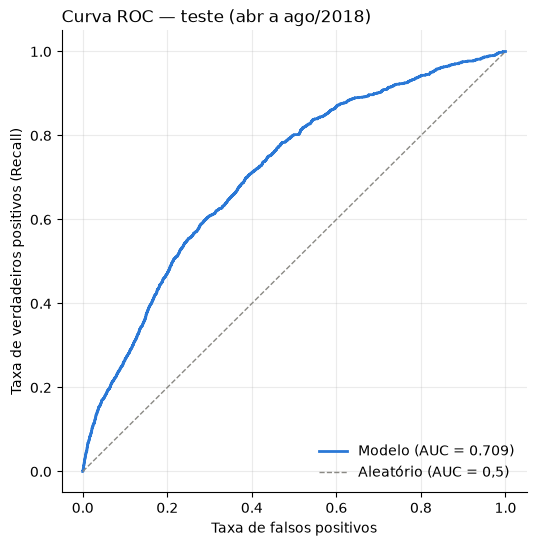

In [3]:
fpr, tpr, _ = roc_curve(preds["y_true"], preds["proba"])

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(fpr, tpr, color=COLOR, linewidth=2, label=f"Modelo (AUC = {metrics['roc_auc']:.3f})")
ax.plot([0, 1], [0, 1], color=GRAY, linewidth=1, linestyle="--", label="Aleatório (AUC = 0,5)")
ax.set_xlabel("Taxa de falsos positivos")
ax.set_ylabel("Taxa de verdadeiros positivos (Recall)")
style(ax, "Curva ROC — teste (abr a ago/2018)")
ax.legend(loc="lower right", frameon=False)
plt.show()

## 3. Curva Precision-Recall

Mais informativa que a ROC quando os atrasos são raros. A linha tracejada é o que um modelo aleatório alcançaria.

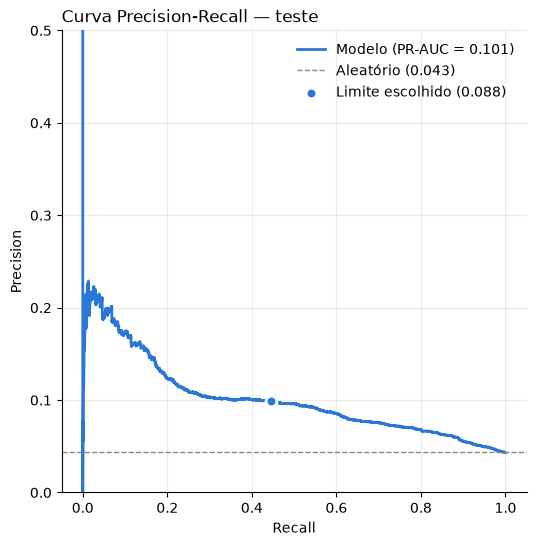

In [4]:
precision, recall, _ = precision_recall_curve(preds["y_true"], preds["proba"])

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(recall, precision, color=COLOR, linewidth=2, label=f"Modelo (PR-AUC = {metrics['pr_auc']:.3f})")
ax.axhline(metrics["baseline_delay_rate"], color=GRAY, linewidth=1, linestyle="--",
           label=f"Aleatório ({metrics['baseline_delay_rate']:.3f})")
ax.scatter([best["recall"]], [best["precision"]], color=COLOR, s=60, zorder=3,
           edgecolor="white", linewidth=2, label=f"Limite escolhido ({best['threshold']:.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_ylim(0, max(0.5, float(np.nanmax(precision[:-1])) * 1.05))
style(ax, "Curva Precision-Recall — teste")
ax.legend(loc="upper right", frameon=False)
plt.show()

## 4. Matriz de confusão (limite escolhido)

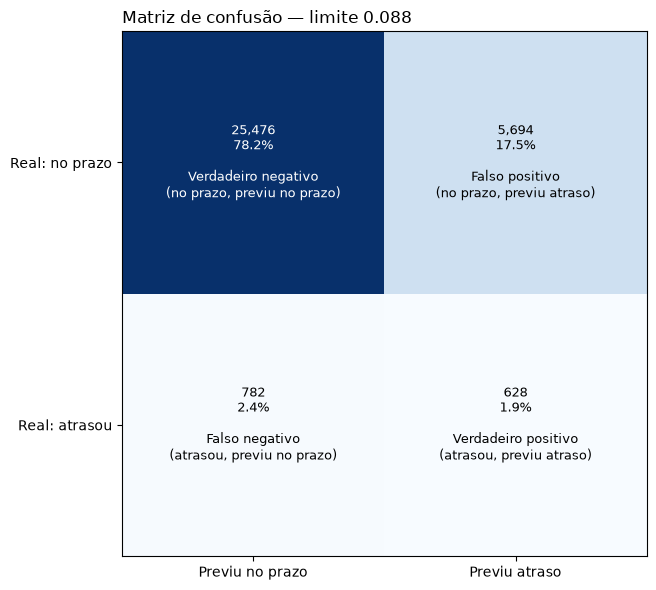

In [5]:
cm = best["confusion_matrix"]
matrix = np.array([[cm["tn"], cm["fp"]], [cm["fn"], cm["tp"]]])
labels = [["Verdadeiro negativo\n(no prazo, previu no prazo)", "Falso positivo\n(no prazo, previu atraso)"],
          ["Falso negativo\n(atrasou, previu no prazo)", "Verdadeiro positivo\n(atrasou, previu atraso)"]]

fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(matrix, cmap="Blues")
for i in range(2):
    for j in range(2):
        share = matrix[i, j] / matrix.sum()
        color = "white" if matrix[i, j] > matrix.max() / 2 else "black"
        ax.text(j, i, f"{matrix[i, j]:,}\n{share:.1%}\n\n{labels[i][j]}",
                ha="center", va="center", fontsize=9, color=color)
ax.set_xticks([0, 1], ["Previu no prazo", "Previu atraso"])
ax.set_yticks([0, 1], ["Real: no prazo", "Real: atrasou"])
ax.set_title(f"Matriz de confusão — limite {best['threshold']:.3f}", loc="left", fontsize=12)
plt.tight_layout()
plt.show()

## 5. Importância das features

As 27 colunas de UF de origem e as 27 de destino foram somadas em "UF de origem" e "UF de destino",
para facilitar a leitura.

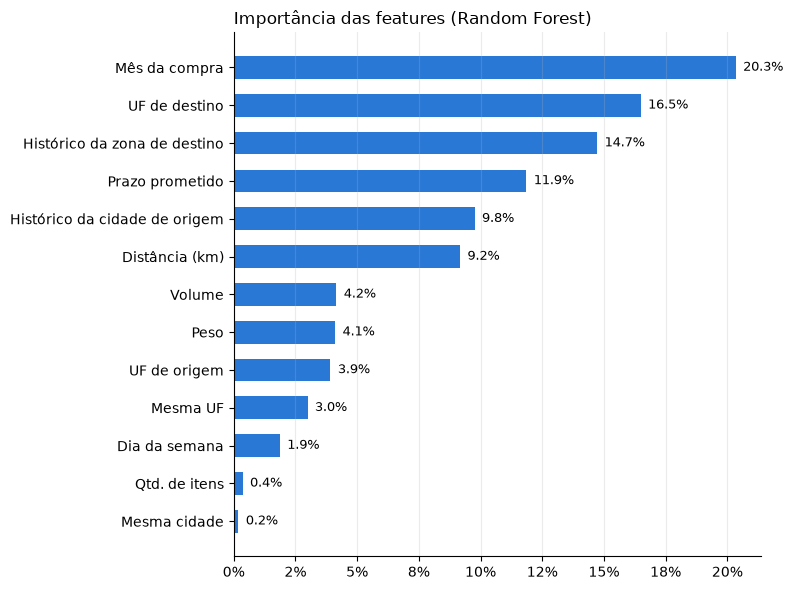

,importância
Mês da compra,0.203
UF de destino,0.165
Histórico da zona de destino,0.147
Prazo prometido,0.119
Histórico da cidade de origem,0.098
Distância (km),0.092
Volume,0.042
Peso,0.041
UF de origem,0.039
Mesma UF,0.030


In [6]:
imp = pd.Series(report["feature_importances"])
grouped = pd.concat([
    imp[~imp.index.str.contains("_uf_")],
    pd.Series({
        "UF de origem": imp[imp.index.str.startswith("origin_uf_")].sum(),
        "UF de destino": imp[imp.index.str.startswith("dest_uf_")].sum(),
    }),
]).sort_values()

names = {
    "distance_km": "Distância (km)", "same_city": "Mesma cidade", "same_state": "Mesma UF",
    "promised_days": "Prazo prometido", "weight_g": "Peso", "volume_cm3": "Volume",
    "n_items": "Qtd. de itens", "purchase_month": "Mês da compra", "purchase_weekday": "Dia da semana",
    "zone_delay_rate": "Histórico da zona de destino", "origin_delay_rate": "Histórico da cidade de origem",
}
grouped.index = [names.get(i, i) for i in grouped.index]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(grouped.index, grouped.values, color=COLOR, height=0.6)
for y, v in enumerate(grouped.values):
    ax.text(v + 0.003, y, f"{v:.1%}", va="center", fontsize=9)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
style(ax, "Importância das features (Random Forest)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

grouped.sort_values(ascending=False).to_frame("importância")

## 6. As faixas de risco funcionam?

Se as faixas fazem sentido, a **taxa de atraso real** precisa subir de baixo → médio → alto.

In [7]:
bands = report["risk_bands"]
preds["faixa"] = np.select(
    [preds["proba"] >= bands["high"], preds["proba"] >= bands["medium"]],
    ["alto", "médio"], default="baixo",
)

by_band = (
    preds.groupby("faixa")
    .agg(envios=("y_true", "size"), atrasados=("y_true", "sum"), taxa_real=("y_true", "mean"))
    .reindex(["baixo", "médio", "alto"])
    .fillna({"envios": 0, "atrasados": 0})
    .astype({"envios": int, "atrasados": int})
)
by_band["% dos envios"] = by_band["envios"] / by_band["envios"].sum()
by_band["vs. média"] = by_band["taxa_real"] / preds["y_true"].mean()

print(f"Faixas: médio >= {bands['medium']:.3f} | alto >= {bands['high']:.3f}")
by_band

Faixas: médio >= 0.044 | alto >= 0.088


,envios,atrasados,taxa_real,% dos envios,vs. média
faixa,,,,,
baixo,11367,158,0.014,0.349,0.321
médio,14901,626,0.042,0.457,0.971
alto,6312,626,0.099,0.194,2.292


## Conclusões

- **ROC-AUC 0,709 / PR-AUC 0,101.** O modelo é 2,3 vezes melhor que o acaso (PR-AUC aleatório = 0,043)
- **Com o limite de 0,088**, o modelo identifica 44,5% dos atrasos (Recall), e 9,9% dos alertas se
  confirmam (Precision). Com o limite padrão de 0,5, não identificaria nenhum atraso
- **Features mais importantes:** mês da compra (20,3%), UF de destino (16,5%), histórico da zona de
  destino (14,7%), prazo prometido (11,9%) e histórico da cidade de origem (9,8%). Somadas, as
  features geográficas respondem por cerca de 57% das decisões
- **Taxa de atraso real por faixa:** baixo 1,4% | médio 4,2% | alto 9,9%. A faixa alta concentra
  19% dos envios e 44% dos atrasos; envios de risco alto atrasam 7 vezes mais que os de risco baixo
- **Limitações:**
  - taxa de atraso diferente entre treino (7,9%) e teste (4,3%), o que reduz a Precision no teste;
  - o efeito dos meses de pico (nov, fev, mar) foi aprendido com apenas um ano de dados;
  - o limite de decisão foi escolhido no próprio período de teste, então Precision, Recall e F1
    são um pouco otimistas (a ROC-AUC não é afetada);
  - causas externas de atraso (clima, greves, transportadora) não estão na base